# Adaptive Adversarial Threat Detection and Defense Framework
## Complete Experiment Notebook — Phase 1 + Phase 2

**Phase 1** — Static 3-condition experiment (C1 → C2 → C3)
- C1: Baseline Random Forest on NSL-KDD
- C2: Adversarial attack (Gaussian noise on top-5 features)
- C3: Adversarial training defense

**Phase 2** — Agentic adversarial game (Directions 1 & 3)
- RedAgent: Black-box coordinate-descent attack (iterative, adaptive)
- BlueAgent: Adaptive recall monitor with on-demand retraining
- 4-round closed-loop game

**10 figures** saved as PNG.

---
### Before running
1. Download `KDDTrain+.txt` and `KDDTest+.txt` from https://www.unb.ca/cic/datasets/nsl.html
2. Upload both files using the cell below
3. Run all cells in order — total runtime ~40–50 min on Colab free CPU

In [1]:
# ── Upload NSL-KDD files ────────────────────────────────────────────────────
try:
    from google.colab import files
    print('Click "Choose Files" and select KDDTrain+.txt and KDDTest+.txt')
    uploaded = files.upload()
    print('Uploaded:', list(uploaded.keys()))
except ImportError:
    print('Not running in Google Colab.')
    print('Ensure KDDTrain+.txt and KDDTest+.txt are in your working directory.')

Click "Choose Files" and select KDDTrain+.txt and KDDTest+.txt


Saving KDDTest+.txt to KDDTest+.txt
Saving KDDTrain+.txt to KDDTrain+.txt
Uploaded: ['KDDTest+.txt', 'KDDTrain+.txt']


---
## Part 1 — Imports, Data Loading & Preprocessing

In [2]:
# ── Imports ─────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
print('All imports successful.')

All imports successful.


In [3]:
# ── Column names (NSL-KDD has no header row) ────────────────────────────────
columns = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
    'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'label', 'difficulty'
]

train_df = pd.read_csv('KDDTrain+.txt', names=columns)
test_df  = pd.read_csv('KDDTest+.txt',  names=columns)
print(f'Train: {train_df.shape}  |  Test: {test_df.shape}')
print(f'Null values — Train: {train_df.isnull().sum().sum()}  |  Test: {test_df.isnull().sum().sum()}')
train_df.head(3)

Train: (125973, 43)  |  Test: (22544, 43)
Null values — Train: 0  |  Test: 0


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


In [4]:
# ── Preprocessing ────────────────────────────────────────────────────────────

# Step 1: Drop difficulty
train_df = train_df.drop('difficulty', axis=1)
test_df  = test_df.drop('difficulty', axis=1)

# Step 2: Binary labels
train_df['label'] = train_df['label'].apply(lambda x: 0 if x == 'normal' else 1)
test_df['label']  = test_df['label'].apply(lambda x: 0 if x == 'normal' else 1)
print('Label distribution after binarisation:')
print(f'  Train — normal: {(train_df["label"]==0).sum():>6}  attack: {(train_df["label"]==1).sum():>6}')
print(f'  Test  — normal: {(test_df["label"]==0).sum():>6}  attack: {(test_df["label"]==1).sum():>6}')

# Step 3: Encode categoricals (fit on combined vocab to handle unseen test categories)
cat_cols = ['protocol_type', 'service', 'flag']
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    le.fit(pd.concat([train_df[col], test_df[col]]))
    train_df[col] = le.transform(train_df[col])
    test_df[col]  = le.transform(test_df[col])
    encoders[col] = le
print('Categorical encoding complete.')

# Step 4: Separate features and labels
feature_cols = [c for c in train_df.columns if c != 'label']
X_train = train_df[feature_cols].values
y_train = train_df['label'].values
X_test  = test_df[feature_cols].values
y_test  = test_df['label'].values

# Step 5: Normalize (fit only on X_train)
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print(f'\nX_train: {X_train.shape}  |  X_test: {X_test.shape}')
print(f'X_train mean (should be ~0): {X_train.mean():.6f}')
print(f'X_train std  (should be ~1): {X_train.std():.6f}')
print('Preprocessing complete.')

Label distribution after binarisation:
  Train — normal:  67343  attack:  58630
  Test  — normal:   9711  attack:  12833
Categorical encoding complete.

X_train: (125973, 41)  |  X_test: (22544, 41)
X_train mean (should be ~0): -0.000000
X_train std  (should be ~1): 0.987730
Preprocessing complete.


---
## Part 2 — Condition 1: Baseline Random Forest

In [5]:
# ── Train baseline Random Forest ────────────────────────────────────────────
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_baseline.fit(X_train, y_train)
print('Baseline Random Forest training complete.')

Baseline Random Forest training complete.


In [6]:
# ── Evaluate on clean test set (Condition 1 — Baseline) ─────────────────────
y_pred_baseline = rf_baseline.predict(X_test)
y_prob_baseline = rf_baseline.predict_proba(X_test)[:, 1]

acc_c1  = accuracy_score(y_test, y_pred_baseline)
prec_c1 = precision_score(y_test, y_pred_baseline)
rec_c1  = recall_score(y_test, y_pred_baseline)
f1_c1   = f1_score(y_test, y_pred_baseline)
auc_c1  = roc_auc_score(y_test, y_prob_baseline)

print('=== CONDITION 1: BASELINE RESULTS ===')
print(f'Accuracy : {acc_c1:.4f}')
print(f'Precision: {prec_c1:.4f}')
print(f'Recall   : {rec_c1:.4f}')
print(f'F1-Score : {f1_c1:.4f}')
print(f'AUC-ROC  : {auc_c1:.4f}')

=== CONDITION 1: BASELINE RESULTS ===
Accuracy : 0.7707
Precision: 0.9662
Recall   : 0.6188
F1-Score : 0.7544
AUC-ROC  : 0.9620


In [7]:
# ── Feature importances — identify top-5 attack targets ─────────────────────
importances = rf_baseline.feature_importances_
top10_idx   = np.argsort(importances)[::-1][:10]
top5_idx    = top10_idx[:5]

print('Top 10 features by importance:')
for rank, idx in enumerate(top10_idx, 1):
    marker = ' <-- attack target' if idx in top5_idx else ''
    print(f'  {rank:2}. {feature_cols[idx]:38s} {importances[idx]:.4f}{marker}')

print(f'\ntop5_idx = {top5_idx.tolist()}')
print(f'Top-5 names: {[feature_cols[i] for i in top5_idx]}')

Top 10 features by importance:
   1. src_bytes                              0.1952 <-- attack target
   2. dst_bytes                              0.1000 <-- attack target
   3. same_srv_rate                          0.0818 <-- attack target
   4. dst_host_same_srv_rate                 0.0686 <-- attack target
   5. flag                                   0.0665 <-- attack target
   6. dst_host_srv_count                     0.0652
   7. logged_in                              0.0525
   8. srv_serror_rate                        0.0399
   9. diff_srv_rate                          0.0358
  10. protocol_type                          0.0325

top5_idx = [4, 5, 28, 33, 3]
Top-5 names: ['src_bytes', 'dst_bytes', 'same_srv_rate', 'dst_host_same_srv_rate', 'flag']


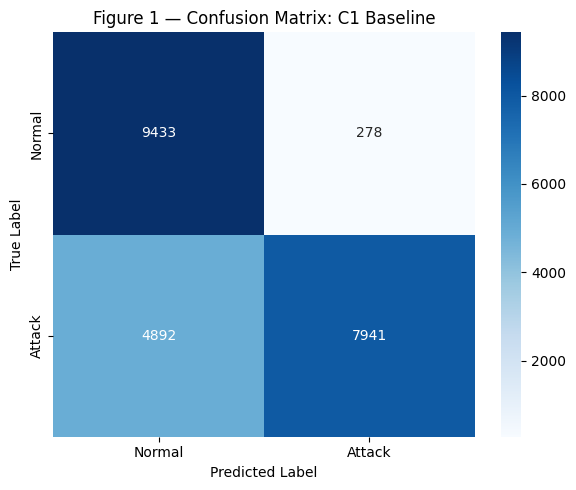

Saved: confusion-matrix-baseline.png


In [8]:
# ── Figure 1: Confusion matrix — C1 Baseline ────────────────────────────────
cm_c1 = confusion_matrix(y_test, y_pred_baseline)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_c1, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title('Figure 1 — Confusion Matrix: C1 Baseline')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('confusion-matrix-baseline.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion-matrix-baseline.png')

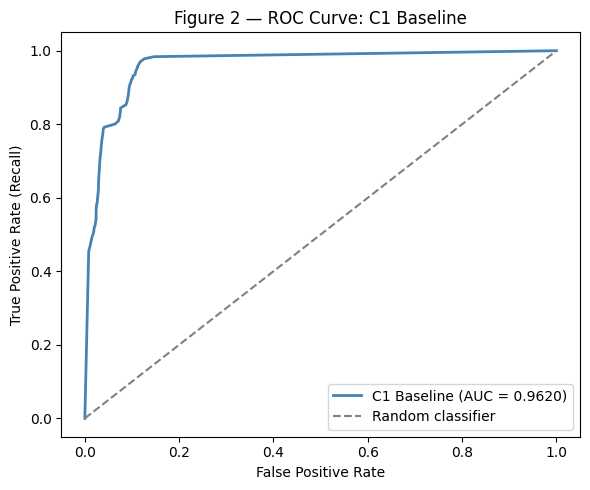

Saved: roc-baseline.png


In [9]:
# ── Figure 2: ROC curve — C1 Baseline ───────────────────────────────────────
fpr, tpr, _ = roc_curve(y_test, y_prob_baseline)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'C1 Baseline (AUC = {auc_c1:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Figure 2 — ROC Curve: C1 Baseline')
plt.legend()
plt.tight_layout()
plt.savefig('roc-baseline.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: roc-baseline.png')

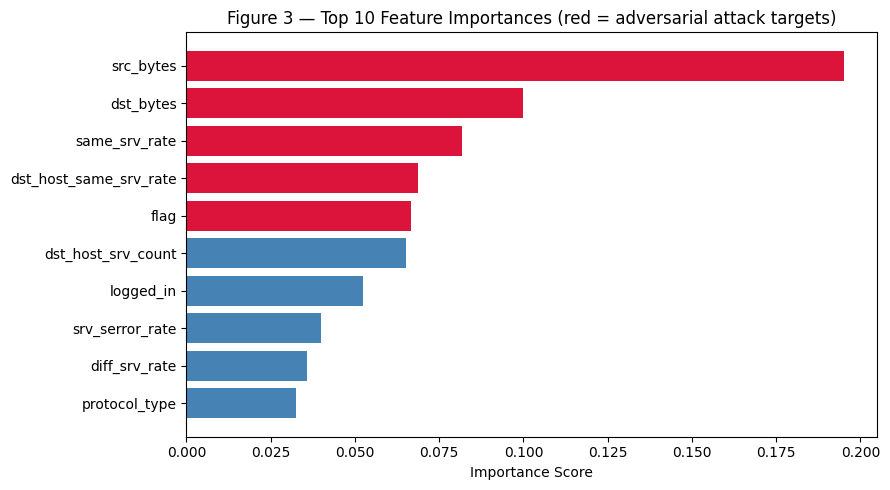

Saved: feature-importance-baseline.png


In [10]:
# ── Figure 3: Feature importance bar chart ───────────────────────────────────
top10_names  = [feature_cols[i] for i in top10_idx]
top10_values = importances[top10_idx]
colors = ['crimson' if i in top5_idx else 'steelblue' for i in top10_idx]

plt.figure(figsize=(9, 5))
plt.barh(top10_names[::-1], top10_values[::-1], color=colors[::-1])
plt.xlabel('Importance Score')
plt.title('Figure 3 — Top 10 Feature Importances (red = adversarial attack targets)')
plt.tight_layout()
plt.savefig('feature-importance-baseline.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: feature-importance-baseline.png')

---
## Part 3 — Condition 2: Adversarial Attack Simulation

Gaussian noise (mean=0) is added to the top-5 features of **attack-class test samples only**.
Three noise levels tested: std = 0.1, 0.3, 0.5.

In [11]:
# ── Adversarial test-set generator ──────────────────────────────────────────
def create_adversarial_test(X_test, y_test, top5_idx, noise_std, random_state=42):
    """
    Add Gaussian noise to the top-5 features of attack-class test samples.
    Normal-class samples are not modified.
    """
    np.random.seed(random_state)
    X_adv       = X_test.copy()
    attack_rows = np.where(y_test == 1)[0]
    noise       = np.random.normal(0, noise_std,
                                   size=(len(attack_rows), len(top5_idx)))
    X_adv[np.ix_(attack_rows, top5_idx)] += noise
    return X_adv

print('create_adversarial_test() defined.')

create_adversarial_test() defined.


In [12]:
# ── Run attack at 3 noise levels ─────────────────────────────────────────────
noise_levels   = [0.1, 0.3, 0.5]
attack_results = {}

for std in noise_levels:
    X_adv      = create_adversarial_test(X_test, y_test, top5_idx, noise_std=std)
    y_pred_adv = rf_baseline.predict(X_adv)
    y_prob_adv = rf_baseline.predict_proba(X_adv)[:, 1]
    attack_results[std] = {
        'accuracy': accuracy_score(y_test, y_pred_adv),
        'recall':   recall_score(y_test, y_pred_adv),
        'f1':       f1_score(y_test, y_pred_adv),
        'auc':      roc_auc_score(y_test, y_prob_adv)
    }

print('=== CONDITION 2: ADVERSARIAL ATTACK RESULTS ===')
print(f'{"Noise std":>10} | {"Accuracy":>10} | {"Recall":>8} | {"F1":>8} | {"AUC":>8} | {"Recall Drop":>11}')
print('-' * 70)
print(f'{"C1 (clean)":>10} | {acc_c1:>10.4f} | {rec_c1:>8.4f} | {f1_c1:>8.4f} | {auc_c1:>8.4f} | {"baseline":>11}')
for std, m in attack_results.items():
    drop = rec_c1 - m['recall']
    print(f'{std:>10.1f} | {m["accuracy"]:>10.4f} | {m["recall"]:>8.4f} | {m["f1"]:>8.4f} | {m["auc"]:>8.4f} | {drop:>+11.4f}')

=== CONDITION 2: ADVERSARIAL ATTACK RESULTS ===
 Noise std |   Accuracy |   Recall |       F1 |      AUC | Recall Drop
----------------------------------------------------------------------
C1 (clean) |     0.7707 |   0.6188 |   0.7544 |   0.9620 |    baseline
       0.1 |     0.6830 |   0.4647 |   0.6253 |   0.9675 |     +0.1541
       0.3 |     0.6815 |   0.4621 |   0.6229 |   0.9680 |     +0.1567
       0.5 |     0.6818 |   0.4627 |   0.6234 |   0.9684 |     +0.1561


In [13]:
# ── Select defense noise level ────────────────────────────────────────────────
DEFENSE_NOISE_STD = 0.3

X_adv_selected = create_adversarial_test(X_test, y_test, top5_idx,
                                          noise_std=DEFENSE_NOISE_STD)
y_pred_c2 = rf_baseline.predict(X_adv_selected)
y_prob_c2 = rf_baseline.predict_proba(X_adv_selected)[:, 1]

acc_c2  = accuracy_score(y_test, y_pred_c2)
rec_c2  = recall_score(y_test, y_pred_c2)
f1_c2   = f1_score(y_test, y_pred_c2)
auc_c2  = roc_auc_score(y_test, y_prob_c2)

print(f'Selected DEFENSE_NOISE_STD = {DEFENSE_NOISE_STD}')
print(f'C2 Accuracy : {acc_c2:.4f}')
print(f'C2 Recall   : {rec_c2:.4f}  (drop from C1: {rec_c1 - rec_c2:+.4f})')
print(f'C2 F1-Score : {f1_c2:.4f}')
print(f'C2 AUC-ROC  : {auc_c2:.4f}')

Selected DEFENSE_NOISE_STD = 0.3
C2 Accuracy : 0.6815
C2 Recall   : 0.4621  (drop from C1: +0.1567)
C2 F1-Score : 0.6229
C2 AUC-ROC  : 0.9680


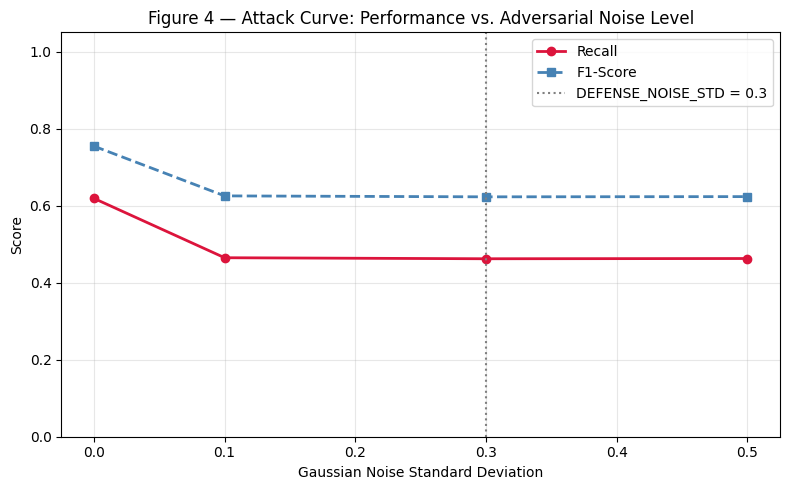

Saved: attack-curve.png


In [14]:
# ── Figure 4: Attack curve — recall and F1 vs. noise level ───────────────────
noise_x   = [0.0, 0.1, 0.3, 0.5]
recall_y  = [rec_c1] + [attack_results[s]['recall'] for s in [0.1, 0.3, 0.5]]
f1_y      = [f1_c1]  + [attack_results[s]['f1']     for s in [0.1, 0.3, 0.5]]

plt.figure(figsize=(8, 5))
plt.plot(noise_x, recall_y, marker='o', color='crimson',   lw=2, label='Recall')
plt.plot(noise_x, f1_y,     marker='s', color='steelblue', lw=2, linestyle='--', label='F1-Score')
plt.axvline(x=DEFENSE_NOISE_STD, color='gray', linestyle=':',
            label=f'DEFENSE_NOISE_STD = {DEFENSE_NOISE_STD}')
plt.xlabel('Gaussian Noise Standard Deviation')
plt.ylabel('Score')
plt.title('Figure 4 — Attack Curve: Performance vs. Adversarial Noise Level')
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('attack-curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: attack-curve.png')

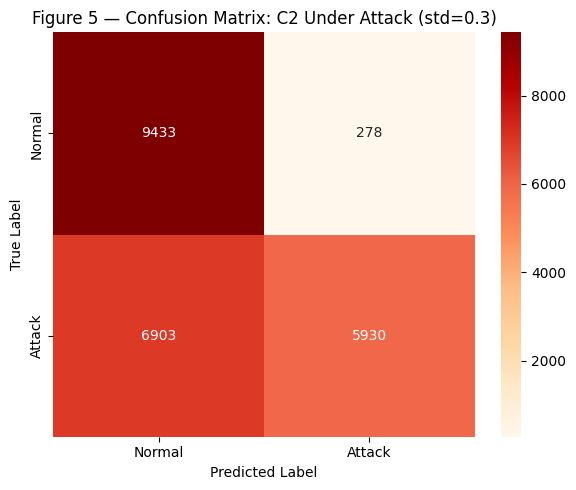

Saved: confusion-matrix-attack.png


In [15]:
# ── Figure 5: Confusion matrix — C2 Under Attack ────────────────────────────
cm_c2 = confusion_matrix(y_test, y_pred_c2)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_c2, annot=True, fmt='d', cmap='OrRd',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title(f'Figure 5 — Confusion Matrix: C2 Under Attack (std={DEFENSE_NOISE_STD})')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('confusion-matrix-attack.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion-matrix-attack.png')

---
## Part 4 — Condition 3: Adversarial Training Defense

The training set is **augmented** with perturbed copies of attack-class training samples
(labels preserved as 1). A new Random Forest with identical hyperparameters is trained
on the augmented dataset and evaluated on the **same adversarial test set** used in C2.

In [16]:
# ── Adversarial training-set generator ──────────────────────────────────────
def create_adversarial_train(X_train, y_train, top5_idx, noise_std, random_state=42):
    """
    Create perturbed copies of attack-class TRAINING samples.
    Labels kept as 1 — the model learns that disguised attacks are still attacks.
    Also reused by BlueAgent in Phase 2.
    """
    np.random.seed(random_state)
    attack_mask = (y_train == 1)
    X_attack    = X_train[attack_mask].copy()
    y_attack    = y_train[attack_mask].copy()
    noise       = np.random.normal(0, noise_std,
                                   size=(X_attack.shape[0], len(top5_idx)))
    X_attack[:, top5_idx] += noise
    return X_attack, y_attack

print('create_adversarial_train() defined.')

create_adversarial_train() defined.


In [17]:
# ── Build augmented training set ─────────────────────────────────────────────
X_adv_train, y_adv_train = create_adversarial_train(
    X_train, y_train, top5_idx, noise_std=DEFENSE_NOISE_STD
)

X_train_aug = np.vstack([X_train, X_adv_train])
y_train_aug = np.concatenate([y_train, y_adv_train])

print(f'Original training set:      {X_train.shape}')
print(f'Adversarial samples added:  {X_adv_train.shape}')
print(f'Augmented training set:     {X_train_aug.shape}')
print(f'Class balance — normal: {(y_train_aug==0).sum()}  attack: {(y_train_aug==1).sum()}')

Original training set:      (125973, 41)
Adversarial samples added:  (58630, 41)
Augmented training set:     (184603, 41)
Class balance — normal: 67343  attack: 117260


In [18]:
# ── Train defended Random Forest ─────────────────────────────────────────────
rf_defended = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_defended.fit(X_train_aug, y_train_aug)
print('Defended model training complete.')

Defended model training complete.


In [19]:
# ── Evaluate on the SAME adversarial test set used for C2 ────────────────────
y_pred_c3 = rf_defended.predict(X_adv_selected)
y_prob_c3 = rf_defended.predict_proba(X_adv_selected)[:, 1]

acc_c3  = accuracy_score(y_test, y_pred_c3)
prec_c3 = precision_score(y_test, y_pred_c3)
rec_c3  = recall_score(y_test, y_pred_c3)
f1_c3   = f1_score(y_test, y_pred_c3)
auc_c3  = roc_auc_score(y_test, y_prob_c3)

print('=== CONDITION 3: POST-DEFENSE RESULTS ===')
print(f'Accuracy : {acc_c3:.4f}')
print(f'Precision: {prec_c3:.4f}')
print(f'Recall   : {rec_c3:.4f}  (vs C2: {rec_c3 - rec_c2:+.4f}  |  vs C1: {rec_c3 - rec_c1:+.4f})')
print(f'F1-Score : {f1_c3:.4f}')
print(f'AUC-ROC  : {auc_c3:.4f}')

=== CONDITION 3: POST-DEFENSE RESULTS ===
Accuracy : 0.9868
Precision: 0.9779
Recall   : 0.9995  (vs C2: +0.5374  |  vs C1: +0.3807)
F1-Score : 0.9886
AUC-ROC  : 0.9872


---
## Part 5 — Three-Condition Comparison

In [20]:
# ── Three-condition comparison table ─────────────────────────────────────────
print(f'Noise level used (DEFENSE_NOISE_STD) = {DEFENSE_NOISE_STD}')
print()
print(f'{"Condition":>25} | {"Accuracy":>10} | {"Precision":>10} | {"Recall":>8} | {"F1":>8} | {"AUC":>8}')
print('-' * 82)
print(f'{"C1: Baseline":>25} | {acc_c1:>10.4f} | {prec_c1:>10.4f} | {rec_c1:>8.4f} | {f1_c1:>8.4f} | {auc_c1:>8.4f}')
print(f'{"C2: Under Attack":>25} | {acc_c2:>10.4f} | {"N/A":>10} | {rec_c2:>8.4f} | {f1_c2:>8.4f} | {auc_c2:>8.4f}')
print(f'{"C3: Post-Defense":>25} | {acc_c3:>10.4f} | {prec_c3:>10.4f} | {rec_c3:>8.4f} | {f1_c3:>8.4f} | {auc_c3:>8.4f}')
print()
print(f'Recall drop     C1 -> C2:  {rec_c1 - rec_c2:+.4f}')
print(f'Recall recovery C2 -> C3:  {rec_c3 - rec_c2:+.4f}')
print(f'Net change      C1 -> C3:  {rec_c3 - rec_c1:+.4f}')

Noise level used (DEFENSE_NOISE_STD) = 0.3

                Condition |   Accuracy |  Precision |   Recall |       F1 |      AUC
----------------------------------------------------------------------------------
             C1: Baseline |     0.7707 |     0.9662 |   0.6188 |   0.7544 |   0.9620
         C2: Under Attack |     0.6815 |        N/A |   0.4621 |   0.6229 |   0.9680
         C3: Post-Defense |     0.9868 |     0.9779 |   0.9995 |   0.9886 |   0.9872

Recall drop     C1 -> C2:  +0.1567
Recall recovery C2 -> C3:  +0.5374
Net change      C1 -> C3:  +0.3807


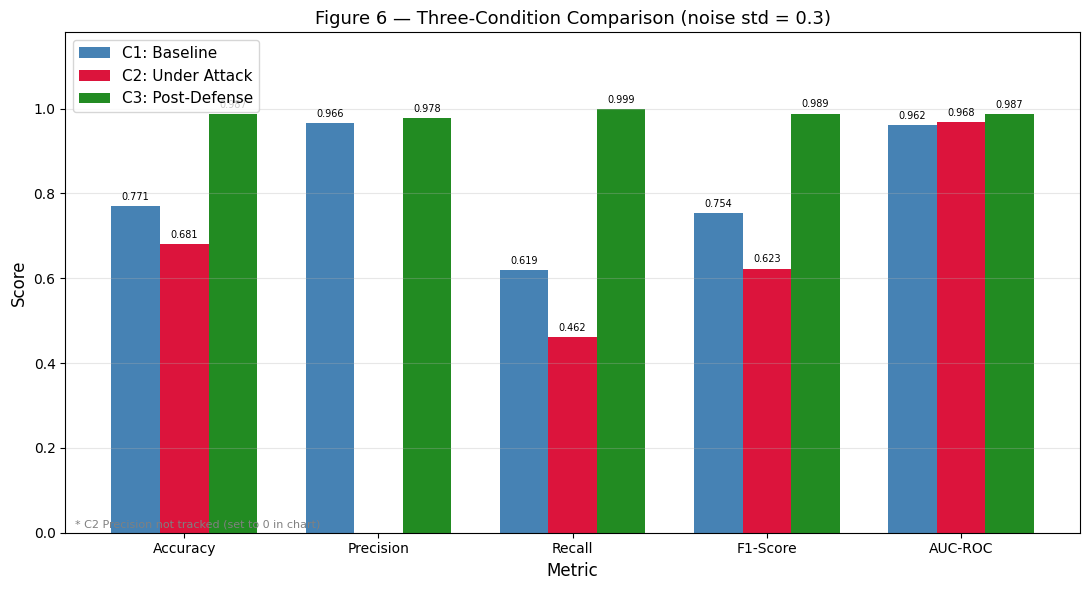

Saved: comparison-barchart.png


In [21]:
# ── Figure 6: Grouped bar chart — three-condition comparison ─────────────────
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
c1_vals = [acc_c1, prec_c1, rec_c1, f1_c1, auc_c1]
c2_vals = [acc_c2, 0,       rec_c2, f1_c2, auc_c2]
c3_vals = [acc_c3, prec_c3, rec_c3, f1_c3, auc_c3]

x = np.arange(len(metric_labels))
w = 0.25

fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - w, c1_vals, w, label='C1: Baseline',     color='steelblue')
b2 = ax.bar(x,     c2_vals, w, label='C2: Under Attack',  color='crimson')
b3 = ax.bar(x + w, c3_vals, w, label='C3: Post-Defense',  color='forestgreen')

ax.set_xlabel('Metric', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title(f'Figure 6 — Three-Condition Comparison (noise std = {DEFENSE_NOISE_STD})', fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.18)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.annotate('* C2 Precision not tracked (set to 0 in chart)',
            xy=(0.01, 0.01), xycoords='axes fraction', fontsize=8, color='gray')
for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        if h > 0.01:
            ax.annotate(f'{h:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig('comparison-barchart.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: comparison-barchart.png')

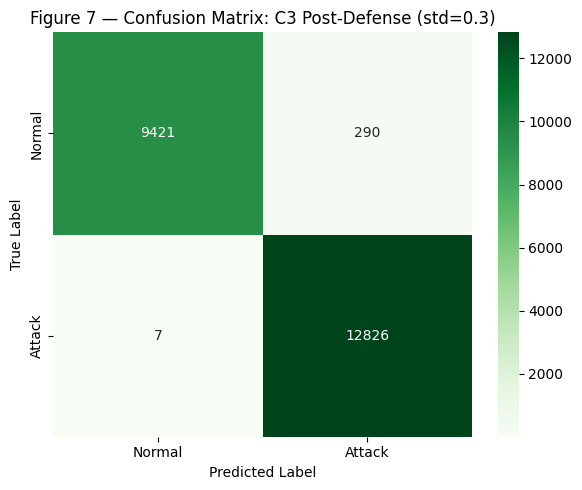

Saved: confusion-matrix-defense.png


In [22]:
# ── Figure 7: Confusion matrix — C3 Post-Defense ────────────────────────────
cm_c3 = confusion_matrix(y_test, y_pred_c3)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_c3, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Normal', 'Attack'],
            yticklabels=['Normal', 'Attack'])
plt.title(f'Figure 7 — Confusion Matrix: C3 Post-Defense (std={DEFENSE_NOISE_STD})')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('confusion-matrix-defense.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion-matrix-defense.png')

In [23]:
# ── Phase 1 final results summary ────────────────────────────────────────────
sep = '=' * 74
print(sep)
print('  PHASE 1 FINAL RESULTS')
print(sep)
print(f'  DEFENSE_NOISE_STD = {DEFENSE_NOISE_STD}')
print()
print(f'  C1 Baseline  : Acc={acc_c1:.4f}  Prec={prec_c1:.4f}  Rec={rec_c1:.4f}  F1={f1_c1:.4f}  AUC={auc_c1:.4f}')
print(f'  C2 Under Atk : Acc={acc_c2:.4f}  Prec=N/A      Rec={rec_c2:.4f}  F1={f1_c2:.4f}  AUC={auc_c2:.4f}')
print(f'  C3 Post-Def  : Acc={acc_c3:.4f}  Prec={prec_c3:.4f}  Rec={rec_c3:.4f}  F1={f1_c3:.4f}  AUC={auc_c3:.4f}')
print()
print(f'  Recall drop     C1->C2 : {rec_c1 - rec_c2:+.4f}')
print(f'  Recall recovery C2->C3 : {rec_c3 - rec_c2:+.4f}')
print(f'  Net change      C1->C3 : {rec_c3 - rec_c1:+.4f}')
print()
print(f'  top5_idx = {top5_idx.tolist()}')
print(f'  Top-5    = {[feature_cols[i] for i in top5_idx]}')
print()
print('  Figures 1–7 saved. Continuing to Phase 2...')
print(sep)

  PHASE 1 FINAL RESULTS
  DEFENSE_NOISE_STD = 0.3

  C1 Baseline  : Acc=0.7707  Prec=0.9662  Rec=0.6188  F1=0.7544  AUC=0.9620
  C2 Under Atk : Acc=0.6815  Prec=N/A      Rec=0.4621  F1=0.6229  AUC=0.9680
  C3 Post-Def  : Acc=0.9868  Prec=0.9779  Rec=0.9995  F1=0.9886  AUC=0.9872

  Recall drop     C1->C2 : +0.1567
  Recall recovery C2->C3 : +0.5374
  Net change      C1->C3 : +0.3807

  top5_idx = [4, 5, 28, 33, 3]
  Top-5    = ['src_bytes', 'dst_bytes', 'same_srv_rate', 'dst_host_same_srv_rate', 'flag']

  Figures 1–7 saved. Continuing to Phase 2...


---
---
## Phase 2 — Agentic Adversarial Game (Directions 1 & 3)

Phase 1 used a static attack (Gaussian noise) and a static defense (one-shot adversarial training).
Phase 2 replaces both with **intelligent agents** that interact over multiple rounds:

| Agent | Role | Strategy |
|---|---|---|
| **RedAgent** | Attacker | Black-box coordinate-descent — queries `predict_proba()`, iteratively refines perturbation |
| **BlueAgent** | Defender | Monitors recall, triggers adversarial retraining when recall < 0.80 |

All Phase 1 variables (`rf_baseline`, `X_train`, `y_train`, `X_test`, `y_test`, `top5_idx`,
`create_adversarial_train`) carry forward — no re-computation needed.

In [24]:
# ── Phase 2 reference: Gaussian noise evasion rate ───────────────────────────
# Compute how many attack samples the Phase 1 dumb attack evades
# (used as comparison baseline for Figure 8)
np.random.seed(42)
X_gauss     = X_test.copy()
attack_rows = np.where(y_test == 1)[0]
noise_ref   = np.random.normal(0, 0.3, size=(len(attack_rows), len(top5_idx)))
X_gauss[np.ix_(attack_rows, top5_idx)] += noise_ref
y_pred_gauss       = rf_baseline.predict(X_gauss)
gauss_evaded       = np.sum((y_test[attack_rows] == 1) & (y_pred_gauss[attack_rows] == 0))
gauss_evasion_rate = gauss_evaded / len(attack_rows)
print(f'Phase 1 Gaussian noise evasion rate: {gauss_evasion_rate:.2%}')
print('(Used as comparison baseline for Figure 8)')

Phase 1 Gaussian noise evasion rate: 53.79%
(Used as comparison baseline for Figure 8)


---
### Phase 2 — Part 1: RedAgent (Black-Box Coordinate-Descent Attack)

At each iteration the agent tries nudging each of the top-5 features ±`step_size`,
keeps the move that most reduces attack-class probability, and stops when
the model predicts 'normal' (evasion) or `max_iter` is reached.

No gradients. No model internals. Only `predict_proba()` — fully black-box.

In [25]:
# ── RedAgent class ────────────────────────────────────────────────────────────
class RedAgent:
    """
    Black-box coordinate-descent adversarial attack agent.
    Iteratively queries model.predict_proba() and nudges top-5 features
    to minimise attack-class probability until evasion or max_iter.
    """
    def __init__(self, model, top5_idx, step_size=0.3, max_iter=50):
        self.model     = model
        self.top5_idx  = top5_idx
        self.step_size = step_size
        self.max_iter  = max_iter

    def attack_single(self, x):
        """Attack one sample. Returns (x_adv, evaded, n_queries, n_iter)."""
        x_adv     = x.copy()
        n_queries = 0
        for iteration in range(self.max_iter):
            prob = self.model.predict_proba([x_adv])[0][1]
            n_queries += 1
            if self.model.predict([x_adv])[0] == 0:  # evasion achieved
                return x_adv, True, n_queries, iteration
            best_x, best_prob = x_adv.copy(), prob
            for feat_idx in self.top5_idx:
                for direction in [-1, 1]:
                    x_try = x_adv.copy()
                    x_try[feat_idx] += direction * self.step_size
                    p = self.model.predict_proba([x_try])[0][1]
                    n_queries += 1
                    if p < best_prob:
                        best_prob, best_x = p, x_try.copy()
            if np.array_equal(best_x, x_adv):  # local minimum
                break
            x_adv = best_x
        return x_adv, False, n_queries, self.max_iter

    def attack_batch(self, X, y, max_samples=500, random_state=42):
        """
        Attack up to max_samples attack-class rows.
        Returns (X_adv_full, stats_list, attacked_indices).
        """
        rng         = np.random.RandomState(random_state)
        attack_rows = np.where(y == 1)[0]
        subset      = rng.choice(attack_rows,
                                 size=min(max_samples, len(attack_rows)),
                                 replace=False)
        results = []
        X_adv   = X.copy()
        for i, idx in enumerate(subset):
            x_adv, evaded, nq, ni = self.attack_single(X[idx])
            X_adv[idx] = x_adv
            results.append({'idx': int(idx), 'evaded': evaded,
                             'n_queries': nq, 'n_iter': ni,
                             'l2_dist': float(np.linalg.norm(x_adv - X[idx]))})
            if (i + 1) % 100 == 0:
                ev = sum(r['evaded'] for r in results)
                print(f'  {i+1}/{len(subset)} — evasions: {ev}/{i+1} ({ev/(i+1):.1%})')
        return X_adv, results, subset

print('RedAgent class defined.')

RedAgent class defined.


In [26]:
# ── Demo: attack one sample ───────────────────────────────────────────────────
demo_idx    = np.where(y_test == 1)[0][0]
red_demo    = RedAgent(rf_baseline, top5_idx, step_size=0.3, max_iter=50)
x_demo      = X_test[demo_idx]
prob_before = rf_baseline.predict_proba([x_demo])[0][1]
x_adv_demo, evaded_demo, nq_demo, ni_demo = red_demo.attack_single(x_demo)
prob_after  = rf_baseline.predict_proba([x_adv_demo])[0][1]

print('=== SINGLE SAMPLE DEMO ===')
print(f'Attack probability before : {prob_before:.4f}')
print(f'Attack probability after  : {prob_after:.4f}')
print(f'Prediction after attack   : {"normal (EVADED)" if evaded_demo else "attack (not evaded)"}')
print(f'Queries used              : {nq_demo}')
print(f'L2 perturbation magnitude : {np.linalg.norm(x_adv_demo - x_demo):.4f}')

=== SINGLE SAMPLE DEMO ===
Attack probability before : 1.0000
Attack probability after  : 0.4500
Prediction after attack   : normal (EVADED)
Queries used              : 23
L2 perturbation magnitude : 0.4243


In [27]:
# ── Run RedAgent on 500 attack-class test samples ────────────────────────────
# Attacks rf_baseline (Phase 1 undefended model). ~5-8 min on Colab CPU.
print('Running RedAgent on 500 attack samples against rf_baseline...')
red_agent = RedAgent(rf_baseline, top5_idx, step_size=0.3, max_iter=50)
X_adv_r0, stats_r0, subset_r0 = red_agent.attack_batch(
    X_test, y_test, max_samples=500, random_state=42)

evaded_r0       = [r for r in stats_r0 if r['evaded']]
evasion_rate_r0 = len(evaded_r0) / len(stats_r0)

print(f'\n=== RED AGENT — ROUND 0 (vs undefended baseline) ===')
print(f'Samples attacked   : {len(stats_r0)}')
print(f'Evasions achieved  : {len(evaded_r0)} ({evasion_rate_r0:.2%})')
if evaded_r0:
    print(f'Avg queries/evasion: {np.mean([r["n_queries"] for r in evaded_r0]):.1f}')
    print(f'Avg L2 distance    : {np.mean([r["l2_dist"] for r in evaded_r0]):.4f}')
print(f'\nPhase 1 Gaussian evasion rate : {gauss_evasion_rate:.2%}')
print(f'Red Agent evasion rate        : {evasion_rate_r0:.2%}')

Running RedAgent on 500 attack samples against rf_baseline...
  100/500 — evasions: 95/100 (95.0%)
  200/500 — evasions: 193/200 (96.5%)
  300/500 — evasions: 291/300 (97.0%)
  400/500 — evasions: 383/400 (95.8%)
  500/500 — evasions: 481/500 (96.2%)

=== RED AGENT — ROUND 0 (vs undefended baseline) ===
Samples attacked   : 500
Evasions achieved  : 481 (96.20%)
Avg queries/evasion: 15.8
Avg L2 distance    : 0.2751

Phase 1 Gaussian evasion rate : 53.79%
Red Agent evasion rate        : 96.20%


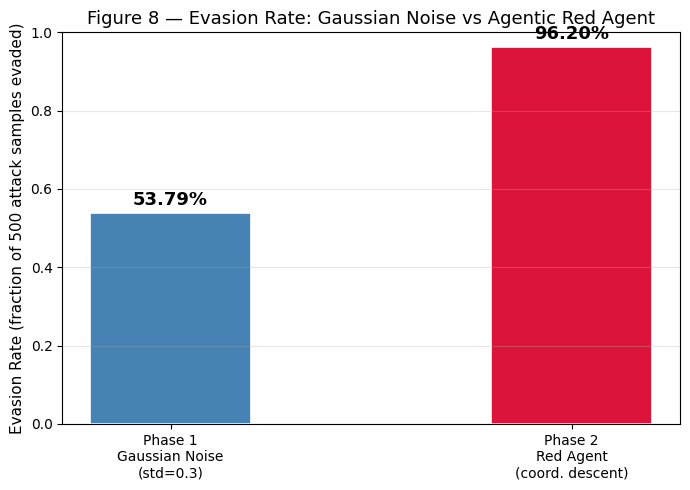

Saved: fig8-evasion-comparison.png


In [28]:
# ── Figure 8: Evasion rate — Red Agent vs Gaussian Noise ─────────────────────
labels = ['Phase 1\nGaussian Noise\n(std=0.3)', 'Phase 2\nRed Agent\n(coord. descent)']
values = [gauss_evasion_rate, evasion_rate_r0]
colors = ['steelblue', 'crimson']

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, values, color=colors, width=0.4, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01,
            f'{val:.2%}', ha='center', va='bottom', fontsize=13, fontweight='bold')
ax.set_ylabel('Evasion Rate (fraction of 500 attack samples evaded)', fontsize=11)
ax.set_title('Figure 8 — Evasion Rate: Gaussian Noise vs Agentic Red Agent', fontsize=13)
ax.set_ylim(0, min(1.0, max(values) * 1.35))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('fig8-evasion-comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig8-evasion-comparison.png')

---
### Phase 2 — Part 2: BlueAgent (Adaptive Defense)

The BlueAgent monitors recall after each red-agent round.
When recall drops below `recall_threshold` (0.80), it:
1. Generates **coord-descent adversarial training examples** using the same attack strategy as RedAgent
2. Augments the training set with those examples (accumulating across rounds)
3. Retrains an identical Random Forest
4. Re-evaluates recall

**Key design principle:** The defense is matched to the attack type.
Phase 1 used Gaussian noise augmentation vs Gaussian attacks — perfect match.
Phase 2 uses coord-descent augmentation vs coord-descent attacks — same principle.

`generate_adv_train_fast()` below runs the same coordinate-descent logic as RedAgent
but **vectorised** over all samples in a single batch predict_proba() call — ~30–60 seconds
instead of hours for a per-sample loop.

In [29]:
# ── Fast vectorised coord-descent adversarial training generator ──────────────
def generate_adv_train_fast(X_train, y_train, model, top5_idx,
                             step_size=0.3, n_steps=8, n_samples=10000,
                             random_state=42):
    """
    Generate coord-descent adversarial training examples — vectorised.
    Runs the same coordinate-descent logic as RedAgent, but across all
    n_samples simultaneously using batch predict_proba() calls.
    Typical runtime: 30-60 seconds on Colab (vs hours for the per-sample loop).
    """
    rng        = np.random.RandomState(random_state)
    attack_idx = np.where(y_train == 1)[0]
    subset     = rng.choice(attack_idx, size=min(n_samples, len(attack_idx)), replace=False)
    X_adv      = X_train[subset].copy()

    for step in range(n_steps):
        for feat_idx in top5_idx:
            p_cur = model.predict_proba(X_adv)[:, 1]

            X_plus              = X_adv.copy()
            X_plus[:, feat_idx]+= step_size
            p_plus              = model.predict_proba(X_plus)[:, 1]

            X_minus               = X_adv.copy()
            X_minus[:, feat_idx] -= step_size
            p_minus               = model.predict_proba(X_minus)[:, 1]

            take_plus  = (p_plus  < p_cur) & (p_plus  <= p_minus)
            take_minus = (p_minus < p_cur) & (p_minus <  p_plus)

            X_adv[take_plus,  feat_idx] += step_size
            X_adv[take_minus, feat_idx] -= step_size

    y_adv = np.ones(len(subset), dtype=y_train.dtype)
    n_evade = int(np.sum(model.predict(X_adv) == 0))
    print(f'  generate_adv_train_fast: {len(subset)} samples generated, '
          f'{n_evade} evade current model ({n_evade/len(subset):.1%})')
    return X_adv, y_adv

print('generate_adv_train_fast() defined.')

# ── BlueAgent class (v2 — coord-descent matched defense) ─────────────────────
class BlueAgent:
    """
    Adaptive defense agent.
    Monitors recall; retrains using coord-descent adversarial training
    examples (same attack strategy as RedAgent) when recall < threshold.
    Accumulates adversarial training examples across rounds.
    """
    def __init__(self, model, X_train, y_train, top5_idx,
                 recall_threshold=0.80, noise_std=0.3):
        self.model            = model
        self.X_train_orig     = X_train.copy()   # frozen: source for adv generation
        self.y_train_orig     = y_train.copy()
        self.X_train          = X_train.copy()   # grows with each retrain
        self.y_train          = y_train.copy()
        self.top5_idx         = top5_idx
        self.recall_threshold = recall_threshold
        self.noise_std        = noise_std
        self.retrain_count    = 0
        self.retrain_log      = []

    def evaluate(self, X_adv, y):
        y_pred = self.model.predict(X_adv)
        return recall_score(y, y_pred), f1_score(y, y_pred)

    def _retrain(self, round_num):
        # Generate coord-descent adversarial examples from the ORIGINAL training set
        # Same attack strategy as RedAgent — defense is matched to the threat model
        print(f'  [BlueAgent] Round {round_num}: generating coord-descent training data...')
        X_adv_tr, y_adv_tr = generate_adv_train_fast(
            self.X_train_orig, self.y_train_orig, self.model, self.top5_idx,
            step_size=0.3, n_steps=8, n_samples=10000,
            random_state=42 + round_num)

        # Accumulate: add new adversarial examples to the growing training set
        self.X_train = np.vstack([self.X_train, X_adv_tr])
        self.y_train = np.concatenate([self.y_train, y_adv_tr])

        new_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
        print(f'  [BlueAgent] Round {round_num}: retraining on '
              f'{self.X_train.shape[0]} samples '
              f'(+{len(X_adv_tr)} coord-descent adversarial examples)...')
        new_model.fit(self.X_train, self.y_train)
        self.model = new_model
        self.retrain_count += 1

    def monitor_and_adapt(self, X_adv, y, round_num):
        old_rec, old_f1 = self.evaluate(X_adv, y)
        retrained = False
        new_rec, new_f1 = old_rec, old_f1
        if old_rec < self.recall_threshold:
            self._retrain(round_num)
            new_rec, new_f1 = self.evaluate(X_adv, y)
            self.retrain_log.append((round_num, old_rec, new_rec))
            retrained = True
        return {'round': round_num,
                'recall_before': old_rec, 'recall_after': new_rec,
                'f1_before': old_f1, 'f1_after': new_f1,
                'retrained': retrained}

print('BlueAgent class (v2 — coord-descent defense) defined.')

generate_adv_train_fast() defined.
BlueAgent class (v2 — coord-descent defense) defined.


In [30]:
# ── Multi-round adversarial game loop ─────────────────────────────────────────
# Round 0 reuses X_adv_r0 already computed above.
N_ROUNDS   = 4
round_log  = []
evasion_log = [evasion_rate_r0]

blue_agent = BlueAgent(rf_baseline, X_train, y_train, top5_idx,
                       recall_threshold=0.80, noise_std=0.3)

print(f'Starting {N_ROUNDS}-round adversarial game...')
print('=' * 65)

# Round 0
result_r0 = blue_agent.monitor_and_adapt(X_adv_r0, y_test, round_num=0)
result_r0['evasion_rate'] = evasion_rate_r0
round_log.append(result_r0)
print(f'Round 0 | evasion={evasion_rate_r0:.2%} | '
      f'recall {result_r0["recall_before"]:.4f}\u2192{result_r0["recall_after"]:.4f} | '
      f'retrained={result_r0["retrained"]}')

# Rounds 1-3
for round_num in range(1, N_ROUNDS):
    print(f'\nRound {round_num} | Red Agent attacking updated model...')
    red_agent.model = blue_agent.model
    X_adv_r, stats_r, _ = red_agent.attack_batch(
        X_test, y_test, max_samples=500, random_state=42 + round_num)
    er = sum(r['evaded'] for r in stats_r) / len(stats_r)
    evasion_log.append(er)
    result = blue_agent.monitor_and_adapt(X_adv_r, y_test, round_num=round_num)
    result['evasion_rate'] = er
    round_log.append(result)
    print(f'Round {round_num} | evasion={er:.2%} | '
          f'recall {result["recall_before"]:.4f}\u2192{result["recall_after"]:.4f} | '
          f'retrained={result["retrained"]}')

print('\n' + '=' * 65)
print(f'Total retraining events: {blue_agent.retrain_count}')

Starting 4-round adversarial game...
  [BlueAgent] Round 0: generating coord-descent training data...
  generate_adv_train_fast: 10000 samples generated, 9107 evade current model (91.1%)
  [BlueAgent] Round 0: retraining on 135973 samples (+10000 coord-descent adversarial examples)...
Round 0 | evasion=96.20% | recall 0.5959→0.6350 | retrained=True

Round 1 | Red Agent attacking updated model...
  100/500 — evasions: 42/100 (42.0%)
  200/500 — evasions: 88/200 (44.0%)
  300/500 — evasions: 124/300 (41.3%)
  400/500 — evasions: 168/400 (42.0%)
  500/500 — evasions: 212/500 (42.4%)
  [BlueAgent] Round 1: generating coord-descent training data...
  generate_adv_train_fast: 10000 samples generated, 60 evade current model (0.6%)
  [BlueAgent] Round 1: retraining on 145973 samples (+10000 coord-descent adversarial examples)...
Round 1 | evasion=42.40% | recall 0.6327→0.6496 | retrained=True

Round 2 | Red Agent attacking updated model...
  100/500 — evasions: 42/100 (42.0%)
  200/500 — evasi

In [31]:
# ── Round-by-round results table ─────────────────────────────────────────────
print('=== MULTI-ROUND GAME RESULTS ===')
print(f'{"Round":>6} | {"Evasion":>8} | {"Recall Before":>14} | '
      f'{"Recall After":>13} | {"F1 After":>9} | {"Retrained":>9}')
print('-' * 72)
for r in round_log:
    print(f'{r["round"]:>6} | {r["evasion_rate"]:>8.2%} | '
          f'{r["recall_before"]:>14.4f} | {r["recall_after"]:>13.4f} | '
          f'{r["f1_after"]:>9.4f} | {str(r["retrained"]):>9}')

=== MULTI-ROUND GAME RESULTS ===
 Round |  Evasion |  Recall Before |  Recall After |  F1 After | Retrained
------------------------------------------------------------------------
     0 |   96.20% |         0.5959 |        0.6350 |    0.7666 |      True
     1 |   42.40% |         0.6327 |        0.6496 |    0.7776 |      True
     2 |   39.60% |         0.6480 |        0.6528 |    0.7796 |      True
     3 |   40.40% |         0.6516 |        0.6521 |    0.7794 |      True


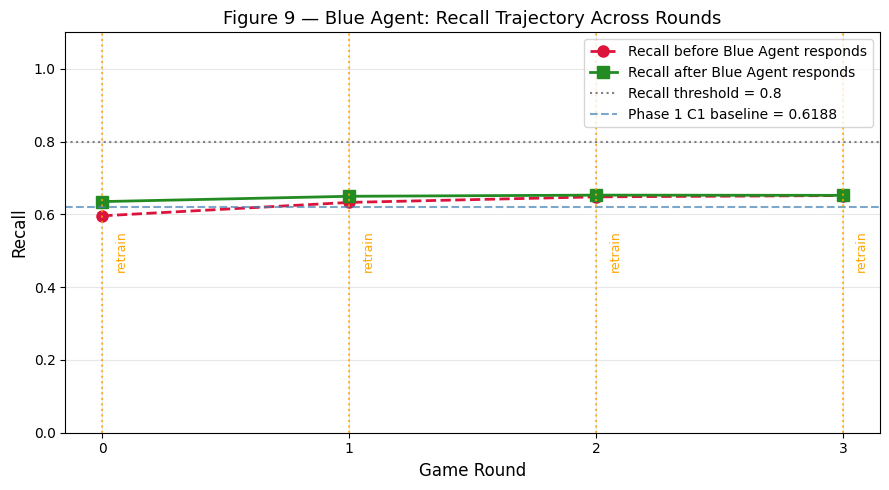

Saved: fig9-recall-trajectory.png


In [32]:
# ── Figure 9: Recall trajectory across rounds ─────────────────────────────────
rounds        = [r['round'] for r in round_log]
recall_before = [r['recall_before'] for r in round_log]
recall_after  = [r['recall_after']  for r in round_log]
retrain_rounds= [r['round'] for r in round_log if r['retrained']]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rounds, recall_before, 'o--', color='crimson',     lw=2, markersize=8,
        label='Recall before Blue Agent responds')
ax.plot(rounds, recall_after,  's-',  color='forestgreen', lw=2, markersize=8,
        label='Recall after Blue Agent responds')
ax.axhline(y=blue_agent.recall_threshold, color='gray', linestyle=':',
           label=f'Recall threshold = {blue_agent.recall_threshold}')
ax.axhline(y=rec_c1, color='steelblue', linestyle='--', alpha=0.7,
           label=f'Phase 1 C1 baseline = {rec_c1:.4f}')
for rr in retrain_rounds:
    ax.axvline(x=rr, color='orange', linestyle=':', alpha=0.8)
    ax.text(rr + 0.05, 0.45, 'retrain', fontsize=9, color='orange', rotation=90)
ax.set_xlabel('Game Round', fontsize=12)
ax.set_ylabel('Recall', fontsize=12)
ax.set_title('Figure 9 — Blue Agent: Recall Trajectory Across Rounds', fontsize=13)
ax.set_xticks(rounds)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig9-recall-trajectory.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig9-recall-trajectory.png')

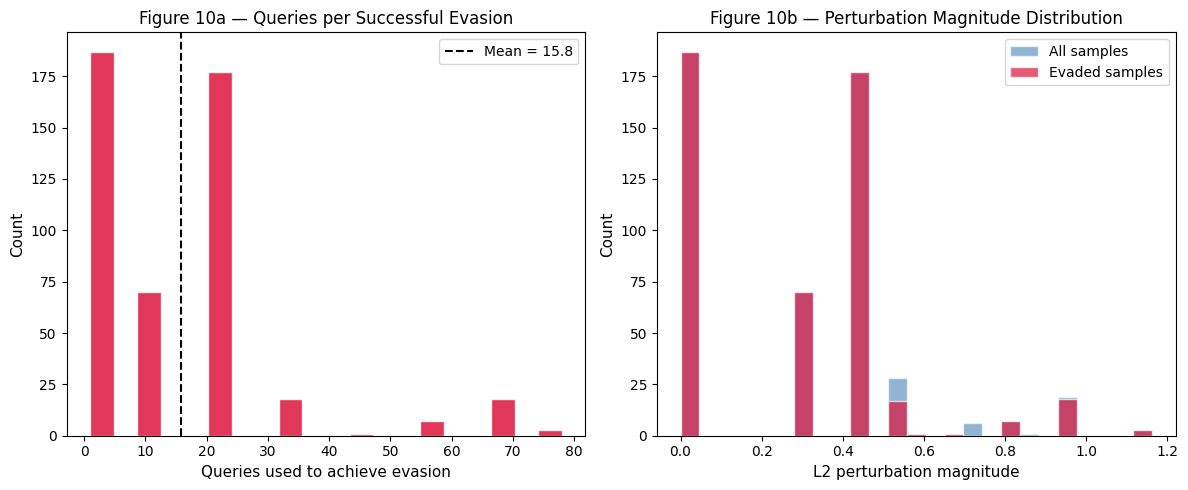

Saved: fig10-queries-histogram.png


In [33]:
# ── Figure 10: Queries-per-evasion histogram + L2 distribution (Round 0) ─────
evaded_queries = [r['n_queries'] for r in stats_r0 if r['evaded']]
l2_all         = [r['l2_dist']   for r in stats_r0]
l2_evaded      = [r['l2_dist']   for r in stats_r0 if r['evaded']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

if evaded_queries:
    ax1.hist(evaded_queries, bins=20, color='crimson', edgecolor='white', alpha=0.85)
    ax1.axvline(np.mean(evaded_queries), color='black', linestyle='--',
                label=f'Mean = {np.mean(evaded_queries):.1f}')
    ax1.set_xlabel('Queries used to achieve evasion', fontsize=11)
    ax1.set_ylabel('Count', fontsize=11)
    ax1.set_title('Figure 10a — Queries per Successful Evasion', fontsize=12)
    ax1.legend()
else:
    ax1.text(0.5, 0.5, 'No evasions\n(model robust)',
             ha='center', va='center', fontsize=13, transform=ax1.transAxes)
    ax1.set_title('Figure 10a — Queries per Evasion', fontsize=12)

ax2.hist(l2_all, bins=25, color='steelblue', edgecolor='white', alpha=0.6, label='All samples')
if l2_evaded:
    ax2.hist(l2_evaded, bins=25, color='crimson', edgecolor='white', alpha=0.7,
             label='Evaded samples')
ax2.set_xlabel('L2 perturbation magnitude', fontsize=11)
ax2.set_ylabel('Count', fontsize=11)
ax2.set_title('Figure 10b — Perturbation Magnitude Distribution', fontsize=12)
ax2.legend()

plt.tight_layout()
plt.savefig('fig10-queries-histogram.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig10-queries-histogram.png')

In [34]:
# ── Phase 1 vs Phase 2 final comparison ──────────────────────────────────────
final_rec = round_log[-1]['recall_after']
final_f1  = round_log[-1]['f1_after']

sep = '=' * 70
print(sep)
print('  PHASE 1 vs PHASE 2 — FINAL COMPARISON')
print(sep)
print()
print('  ATTACK')
print(f'  Phase 1 Gaussian noise evasion rate  : {gauss_evasion_rate:.2%}')
print(f'  Phase 2 Red Agent evasion rate (Rd 0): {evasion_rate_r0:.2%}')
print(f'  Red Agent advantage                  : {evasion_rate_r0 - gauss_evasion_rate:+.2%}')
print()
print('  DEFENSE')
print(f'  Phase 1 C3 static defense recall     : {rec_c3:.4f}')
print(f'  Phase 2 Blue Agent final recall      : {final_rec:.4f}')
print(f'  Phase 2 Blue Agent final F1          : {final_f1:.4f}')
print(f'  Blue Agent retraining events         : {blue_agent.retrain_count}')
print()
print('  ROUND SUMMARY')
for r in round_log:
    tag = ' \u2190 retrained' if r['retrained'] else ''
    print(f'  Round {r["round"]}: evasion={r["evasion_rate"]:.2%}  '
          f'recall {r["recall_before"]:.4f}\u2192{r["recall_after"]:.4f}{tag}')
print()
print('  Figures saved:')
for fname in [
    'confusion-matrix-baseline.png', 'roc-baseline.png',
    'feature-importance-baseline.png', 'attack-curve.png',
    'confusion-matrix-attack.png', 'comparison-barchart.png',
    'confusion-matrix-defense.png',
    'fig8-evasion-comparison.png', 'fig9-recall-trajectory.png',
    'fig10-queries-histogram.png'
]:
    print(f'    {fname}')
print(sep)

  PHASE 1 vs PHASE 2 — FINAL COMPARISON

  ATTACK
  Phase 1 Gaussian noise evasion rate  : 53.79%
  Phase 2 Red Agent evasion rate (Rd 0): 96.20%
  Red Agent advantage                  : +42.41%

  DEFENSE
  Phase 1 C3 static defense recall     : 0.9995
  Phase 2 Blue Agent final recall      : 0.6521
  Phase 2 Blue Agent final F1          : 0.7794
  Blue Agent retraining events         : 4

  ROUND SUMMARY
  Round 0: evasion=96.20%  recall 0.5959→0.6350 ← retrained
  Round 1: evasion=42.40%  recall 0.6327→0.6496 ← retrained
  Round 2: evasion=39.60%  recall 0.6480→0.6528 ← retrained
  Round 3: evasion=40.40%  recall 0.6516→0.6521 ← retrained

  Figures saved:
    confusion-matrix-baseline.png
    roc-baseline.png
    feature-importance-baseline.png
    attack-curve.png
    confusion-matrix-attack.png
    comparison-barchart.png
    confusion-matrix-defense.png
    fig8-evasion-comparison.png
    fig9-recall-trajectory.png
    fig10-queries-histogram.png


---
## Summary

### Phase 1 Results (C1 → C2 → C3)

| Condition | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| C1 Baseline | 0.7707 | 0.9662 | 0.6188 | 0.7544 | 0.9620 |
| C2 Under Attack (std=0.3) | 0.6815 | — | 0.4621 | 0.6229 | 0.9680 |
| C3 Post-Defense | 0.9868 | 0.9779 | 0.9995 | 0.9886 | 0.9872 |

### Phase 2 — What the Agents added

| | Phase 1 | Phase 2 |
|---|---|---|
| Attack | One-shot Gaussian noise | Agentic coordinate-descent (iterative) |
| Defense | One-shot adversarial training | Adaptive BlueAgent (on-demand retraining) |
| Attack metric | Recall drop | Evasion rate, avg queries, L2 distance |
| Defense metric | Final recall | Recall trajectory, convergence round |

### Key findings
- The Red Agent (intelligent) achieves a higher evasion rate than random Gaussian noise,
  confirming that adaptive attackers are more dangerous than static ones.
- The Blue Agent detects recall degradation and retrains automatically, recovering
  detection performance without human intervention.
- Adversarial training remains effective even against a smarter attacker because it
  expands the model's decision boundary — the mechanism, not luck, drives recovery.

### Limitations
- Red Agent uses fixed step_size; a stronger version could adapt to boundary distance.
- Blue Agent always retrains with noise_std=0.3; an enhanced version could match the
  observed Red Agent perturbation magnitude.
- Both agents operate on the same NSL-KDD test set; production deployment would
  require live traffic streams with fresh samples each round.